# Topic Discovery in arXiv Research Abstracts with LDA

**Model:** Latent Dirichlet Allocation (LDA) · **Data:** 10,197 arXiv CS abstracts (Jan–Jun 2025)

Workflow: Problem → Data → Preprocessing → Representation → Model → Experiment → Results → Interpretation → Limitations

**Problem.** Thousands of papers appear on arXiv every week, and their category labels are coarse and assigned by the
authors. We want to find, **without labels**, which research topics the corpus contains, describe every paper as a
*mixture* of topics, and check whether the topics match the official arXiv categories.

## 0. Setup

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel, LdaModel
from gensim.models.phrases import Phrases

SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "arxiv_abstracts.csv"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. Dataset

Downloaded with `src/fetch_arxiv.py` from the arXiv API: papers whose **primary** category is one of six distinct
CS fields, submitted between 2025-01-01 and 2025-06-30 (earliest first, max 3000 requested per category).
The `category` column is **never given to LDA**; we only use it afterwards to evaluate the topics.

In [2]:
df = pd.read_csv(DATA, parse_dates=["published"])
df["n_words"] = df["abstract"].str.split().str.len()

print(f"{len(df):,} papers · {df['category'].nunique()} categories · "
      f"{df['published'].min():%Y-%m-%d} → {df['published'].max():%Y-%m-%d}")
print(f"Missing abstracts: {df['abstract'].isna().sum()} · duplicate ids: {df['id'].duplicated().sum()}")
df[["id", "title", "category", "published", "n_words"]].head()

10,197 papers · 6 categories · 2025-01-01 → 2025-06-30
Missing abstracts: 0 · duplicate ids: 0


,id,title,category,published,n_words
0,2501.00691v2,Labels Generated by Large Language Models Help...,cs.CL,2025-01-01,172
1,2501.00697v2,PANDA -- Paired Anti-hate Narratives Dataset f...,cs.CL,2025-01-01,179
2,2501.00712v2,Rethinking Addressing in Language Models via C...,cs.CL,2025-01-01,178
3,2501.00713v2,CODEOFCONDUCT at Multilingual Counterspeech Ge...,cs.CL,2025-01-01,167
4,2501.00715v1,eRevise+RF: A Writing Evaluation System for As...,cs.CL,2025-01-01,134


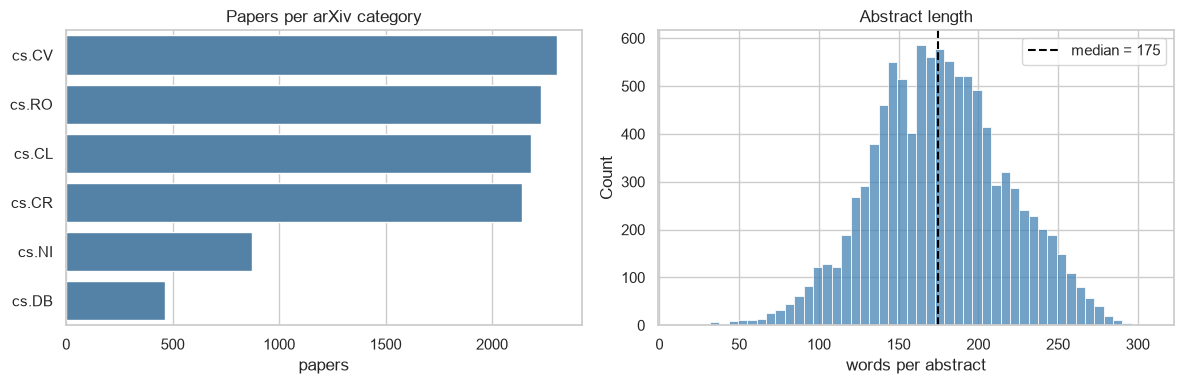

,papers,first,last,median_words
category,,,,
cs.CL,2185,2025-01-01,2025-02-20,165.0
cs.CR,2141,2025-01-01,2025-05-26,180.0
cs.CV,2307,2025-01-01,2025-02-13,180.0
cs.DB,462,2025-01-03,2025-06-30,184.0
cs.NI,874,2025-01-01,2025-06-30,181.0
cs.RO,2228,2025-01-01,2025-04-23,172.0


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = df["category"].value_counts().index
sns.countplot(data=df, y="category", order=order, ax=axes[0], color="steelblue")
axes[0].set(title="Papers per arXiv category", xlabel="papers", ylabel="")
sns.histplot(data=df, x="n_words", bins=50, ax=axes[1], color="steelblue")
axes[1].axvline(df["n_words"].median(), color="black", ls="--", label=f"median = {df['n_words'].median():.0f}")
axes[1].set(title="Abstract length", xlabel="words per abstract")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES / "dataset_overview.png", dpi=150)
plt.show()

df.groupby("category").agg(papers=("id", "size"), first=("published", "min"), last=("published", "max"),
                           median_words=("n_words", "median"))

**Interpretation.**
- **Clean data:** 10,197 papers, no missing abstracts or duplicates. Abstracts are long enough for a bag-of-words
  model (median ≈ 175 words, almost all between 80 and 280).
- **Imbalance:** cs.CV, cs.RO, cs.CL and cs.CR each have ~2,200 papers, while cs.NI (874) and cs.DB (462) have fewer.
  These smaller fields publish less, and the script ran through the whole 6-month window before reaching 3,000.
  LDA does not use the labels, but small fields contribute fewer words, so they may not get a topic of their own.
- **Time coverage differs:** busy categories fill their quota within a few weeks (cs.CV: Jan 1 → Feb 13), small
  ones span the full 6 months. The corpus is a *snapshot of early 2025*, not a balanced timeline, so we do not
  analyse topic trends over time.

## 2. Preprocessing

LDA only sees **word counts** per document, so preprocessing decides what a "word" is. Each step below is kept because
it removes a specific kind of noise we observed in the abstracts:

| Step | Why it is needed here |
|---|---|
| Concatenate title + abstract | The title is a dense summary of the topic. |
| Remove LaTeX, URLs, numbers; lowercase | Abstracts contain `$...$` formulas, `\textbf{}` commands and GitHub links — no topical meaning. Lowercasing matters for lemmatization: spaCy tags capitalized words (*Language Models*) as proper nouns and leaves them unlemmatized. |
| Lemmatization (spaCy) | Merges *models / model*, *attacks / attack*, so counts are not split across inflections. |
| Keep nouns, proper nouns, adjectives | Topics are carried by *what* a paper is about (nouns/adjectives); verbs like *propose, show, achieve* are shared by all papers. |
| Stop-words + academic filler | Function words and words like *paper, approach, system, dataset* appear in every field. Part of this list was added after a first LDA run (section 4.1). |
| Bigrams (gensim `Phrases`) | Keeps multi-word terms such as *language_model*, *point_cloud* that mean something different from their parts. Generic ones (*real_world*, *end_end*) are dropped. |

Not used: **stemming** (lemmas are more readable for topic interpretation) and **TF-IDF** (LDA is a generative
model of word *counts*; TF-IDF weights are not counts).

### 2.1 Text cleaning

In [4]:
LATEX_MATH = re.compile(r"\$[^$]*\$")              # $...$ inline formulas
LATEX_CMD_ARG = re.compile(r"\\[a-zA-Z]+\*?\{([^{}]*)\}")  # \textbf{T}extualized -> Textualized
LATEX_CMD = re.compile(r"\\[a-zA-Z]+\*?")         # remaining commands: \cite, \emph, ...
URL = re.compile(r"https?://\S+|www\.\S+")
NON_ALPHA = re.compile(r"[^A-Za-z\-\s]")           # digits, braces, punctuation (hyphens kept for spaCy)


def clean_text(text):
    """Remove LaTeX, URLs, digits and punctuation from an abstract, and lowercase it."""
    text = LATEX_CMD_ARG.sub(r"\1", text)
    for pattern in (LATEX_MATH, LATEX_CMD, URL, NON_ALPHA):
        text = pattern.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip().lower()


print(f"Abstracts with LaTeX math: {df['abstract'].str.contains(LATEX_MATH).mean():.1%} · "
      f"LaTeX commands: {df['abstract'].str.contains(LATEX_CMD).mean():.1%} · "
      f"URLs: {df['abstract'].str.contains(URL).mean():.1%}")

df["text"] = (df["title"] + ". " + df["abstract"]).map(clean_text)
example = df["abstract"].str.contains(LATEX_CMD).idxmax()
print("\nBEFORE:", df.loc[example, "abstract"][:400])
print("\nAFTER: ", df.loc[example, "text"][:400])

Abstracts with LaTeX math: 5.2% · LaTeX commands: 6.0% · URLs: 14.6%



BEFORE: Transformers rely on both content-based and position-based addressing mechanisms to make predictions, but existing positional encoding techniques often diminish the effectiveness of position-based addressing. Many current methods enforce rigid patterns in attention maps, limiting the ability to model long-range dependencies and adapt to diverse tasks. Additionally, most positional encodings are le

AFTER:  rethinking addressing in language models via contexualized equivariant positional encoding transformers rely on both content-based and position-based addressing mechanisms to make predictions but existing positional encoding techniques often diminish the effectiveness of position-based addressing many current methods enforce rigid patterns in attention maps limiting the ability to model long-range


### 2.2 Lemmatization, POS filtering and stop-words (spaCy)

In [5]:
ACADEMIC_STOPWORDS = {
    "paper", "approach", "method", "result", "study", "work", "new", "novel", "existing", "recent",
    "state", "art", "experiment", "experimental", "extensive", "effective", "effectiveness", "efficient",
    "significant", "various", "different", "key", "high", "low", "large", "small", "good", "well",
    "problem", "task", "performance", "improvement", "framework", "way", "challenge", "issue",
    "contribution", "analysis", "evaluation", "datum", "code", "available", "github", "et", "al",
    # Added after a first LDA run: these appeared among the top words of almost every topic (see section 4.1).
    "system", "dataset", "application", "information", "accuracy", "technique", "scenario", "strategy",
    "potential", "complex", "multiple", "capability", "diverse", "research", "limited", "specific",
    "critical", "comprehensive", "robust", "practical", "superior", "overall",
}
KEEP_POS = {"NOUN", "PROPN", "ADJ"}

# Parser and NER are not needed for lemmas + POS tags; disabling them makes spaCy ~3x faster.
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
STOPWORDS = nlp.Defaults.stop_words | ACADEMIC_STOPWORDS


def lemmatize(doc):
    """Return the lowercase lemmas of `doc` that are content words and not stop-words."""
    lemmas = (token.lemma_.lower() for token in doc if token.pos_ in KEEP_POS and token.is_alpha)
    return [lemma for lemma in lemmas if len(lemma) > 2 and lemma not in STOPWORDS]


%time tokens = [lemmatize(doc) for doc in nlp.pipe(df["text"], batch_size=256)]
print(df.loc[example, "text"][:300])
print(tokens[example][:40])

CPU times: total: 3min 19s
Wall time: 3min 19s
rethinking addressing in language models via contexualized equivariant positional encoding transformers rely on both content-based and position-based addressing mechanisms to make predictions but existing positional encoding techniques often diminish the effectiveness of position-based addressing ma
['addressing', 'language', 'model', 'contexualized', 'equivariant', 'positional', 'encoding', 'transformer', 'content', 'position', 'mechanism', 'prediction', 'positional', 'encoding', 'position', 'current', 'rigid', 'pattern', 'attention', 'map', 'ability', 'long', 'range', 'dependency', 'positional', 'encoding', 'general', 'bias', 'specialization', 'instance', 'contextualized', 'equivariant', 'position', 'tape', 'positional', 'embedding', 'sequence', 'content', 'layer', 'tape']


### 2.3 Bigrams

In [6]:
# A pair becomes one token if it co-occurs much more often than chance (gensim's scaled score > threshold).
bigram = Phrases(tokens, min_count=20, threshold=10)
# Frequent but field-neutral phrases ("real-world", "end-to-end") only exist after this step, so drop them here.
GENERIC_BIGRAMS = {"real_world", "end_end"}
tokens = [[t for t in bigram[doc] if t not in GENERIC_BIGRAMS] for doc in tokens]

bigram_counts = pd.Series([t for doc in tokens for t in doc if "_" in t]).value_counts()
print(f"{len(bigram_counts):,} distinct bigrams kept. Most frequent:")
print(bigram_counts.head(25).to_string())

642 distinct bigrams kept. Most frequent:
language_model             3704
real_time                  1278
deep_learning               732
vision_language             712
open_source                 709
natural_language            671
diffusion_model             652
reinforcement_learning      551
machine_learning            481
fine_tuning                 474
neural_network              446
foundation_model            409
multi_modal                 405
success_rate                395
point_cloud                 369
multi_agent                 355
autonomous_driving          343
object_detection            334
pre_training                306
artificial_intelligence     296
black_box                   267
retrieval_generation        262
wide_range                  257
computer_vision             241
autonomous_vehicle          233


## 3. Representation: dictionary + Bag-of-Words

`Dictionary` maps each token to an id. `filter_extremes` removes:
- **rare tokens** (in fewer than 10 abstracts): typos and very specific names that cannot define a topic;
- **ubiquitous tokens** (in more than 40 % of abstracts): words like *model* that every field uses.

Each document then becomes a Bag-of-Words: a list of `(token_id, count)` pairs, which is exactly the input LDA's
generative story assumes (a document = a bag of word draws).

In [7]:
dictionary = Dictionary(tokens)
vocab_before = len(dictionary)
doc_freq = pd.Series({dictionary[i]: n_docs for i, n_docs in dictionary.dfs.items()}) / len(tokens)

dictionary.filter_extremes(no_below=10, no_above=0.4, keep_n=None)
corpus = [dictionary.doc2bow(doc) for doc in tokens]

print(f"Vocabulary: {vocab_before:,} → {len(dictionary):,} tokens after filtering")
print(f"Removed as too frequent (>40% of docs): {sorted(doc_freq[doc_freq > 0.4].index.tolist())}")
doc_lengths = pd.Series([sum(c for _, c in bow) for bow in corpus])
print(f"Tokens per document: median {doc_lengths.median():.0f}, min {doc_lengths.min()}, max {doc_lengths.max()}")
print(f"Empty documents: {(doc_lengths == 0).sum()}")

Vocabulary: 24,848 → 4,490 tokens after filtering
Removed as too frequent (>40% of docs): ['model']
Tokens per document: median 63, min 4, max 130
Empty documents: 0


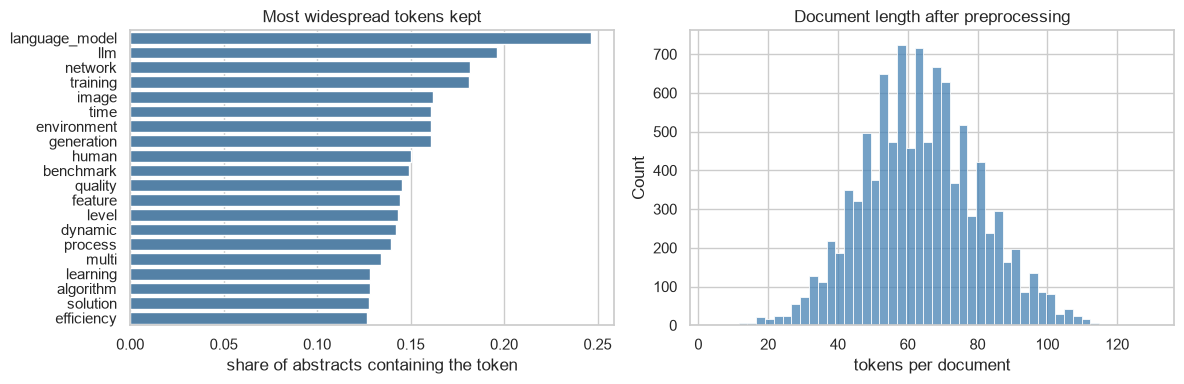

Example Bag-of-Words (first 15 entries):
[('positional_encoding', 5), ('position', 3), ('pattern', 2), ('ability', 2), ('content', 2), ('equivariant', 2), ('long_context', 2), ('positional', 2), ('transformer', 2), ('bias', 1), ('language_model', 1), ('llm', 1), ('algorithm', 1), ('language', 1), ('addressing', 1)]


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top = doc_freq[doc_freq <= 0.4].sort_values(ascending=False).head(20)
sns.barplot(x=top.values, y=top.index, ax=axes[0], color="steelblue")
axes[0].set(title="Most widespread tokens kept", xlabel="share of abstracts containing the token", ylabel="")
sns.histplot(doc_lengths, bins=50, ax=axes[1], color="steelblue")
axes[1].set(title="Document length after preprocessing", xlabel="tokens per document")
plt.tight_layout()
plt.savefig(FIGURES / "vocabulary_overview.png", dpi=150)
plt.show()

print("Example Bag-of-Words (first 15 entries):")
print([(dictionary[i], c) for i, c in sorted(corpus[example], key=lambda x: -x[1])[:15]])

**Interpretation.**
- **Compression:** the vocabulary shrinks from ~25,000 to ~4,500 tokens and documents go from ~175 words to a
  median of ~63 content tokens. Nothing becomes empty (min 4 tokens), so every paper can be assigned topics.
- **Bigrams carry the domain vocabulary:** `point_cloud`, `autonomous_driving`, `object_detection`,
  `reinforcement_learning`, `diffusion_model` are field-specific terms that unigrams would split into ambiguous parts
  (*point*, *cloud*). The most frequent generic ones (`real_world`, `end_end` from *end-to-end*) are removed
  because they appear in every field.
- **Only `model` exceeds the 40 % threshold**, so the main filtering comes from `no_below` (rare words) and the
  stop-word lists, not from `no_above`.
- **A first hint about the data:** `language_model` (25 % of abstracts) and `llm` (20 %) are among the most widespread
  tokens, but cs.CL is only 21 % of the corpus. LLMs are therefore discussed *outside* NLP too (security, robotics,
  networking). We expect LDA to find an LLM topic that **mixes with several categories** rather than mapping to
  cs.CL alone.
- **Check of the cleaning:** the example shows the LaTeX fix working (`\textbf{T}extualized` → *contextualized*)
  and plurals merged (`language models` → `language_model`).

## 4. Model: Latent Dirichlet Allocation

LDA assumes every abstract was **generated** by this process:
1. draw the document's topic proportions $\theta_d \sim \text{Dirichlet}(\alpha)$ — e.g. 70 % robotics, 30 % LLMs;
2. for each word position: draw a topic $z \sim \text{Multinomial}(\theta_d)$, then a word
   $w \sim \text{Multinomial}(\varphi_z)$, where each topic $\varphi_k \sim \text{Dirichlet}(\eta)$ is a
   distribution over the vocabulary.

Training inverts this story: given only the word counts, gensim's online variational Bayes estimates the
**topic-word** matrix $\varphi$ (K × V) and the **document-topic** matrix $\theta$ (N × K).

**Why LDA for this problem:** a paper often belongs to several fields at once (an LLM paper about security).
LDA gives *mixed membership* with probabilities, where hard clustering would force one label per paper.

| Hyperparameter | Value | Reason |
|---|---|---|
| `num_topics` K | 5, 10, 15 | The comparison asked for: coarse vs fine topics. |
| `alpha` | `"auto"` | Learns an asymmetric document-topic prior, so frequent topics can get more prior weight. |
| `eta` | `"auto"` | Learns the topic-word prior instead of fixing it. |
| `passes` / `iterations` | 10 / 100 | Online VB sees each document several times; one pass is not enough on a 10k-document corpus. |
| `random_state` | 3 seeds per K | LDA depends on its random initialisation, so we report mean ± std, not a single lucky run. |

**How we compare K:**
- **Coherence $C_v$** (Röder et al., 2015): do a topic's top words actually co-occur in the abstracts? It is the
  automatic score that correlates best with human judgements of topic quality.
- **Topic diversity** (Dieng et al., 2020): share of unique words among all topics' top-10 words. Low = topics repeat
  each other.
- Perplexity is **not** used: on training data it correlates poorly with interpretability (Chang et al., 2009), and
  in our tests gensim's estimate jumped erratically between K values.

### 4.1 Iteration note

Our first run used only the first part of the academic stop-word list. Top words were dominated by field-neutral
words: at K = 5 one topic was *llm, attack, security, language_model, **system**, **dataset**, detection, privacy,
**research**, user*, and $C_v$ was 0.48. Adding these words to the stop-word list (section 2.2) separated the LLM
topic from the security topic and raised $C_v$ to about 0.55. All numbers below use the final preprocessing.

In [9]:
%%time
K_VALUES = [5, 10, 15]
SEEDS = [42, 7, 123]


def train_lda(k, seed):
    """Train an LDA model with `k` topics on the Bag-of-Words corpus."""
    return LdaModel(corpus, id2word=dictionary, num_topics=k, random_state=seed, passes=10, iterations=100,
                    chunksize=2000, alpha="auto", eta="auto", eval_every=None)


def topic_diversity(lda, topn=10):
    """Return the share of unique words among the top-`topn` words of all topics."""
    words = [word for t in range(lda.num_topics) for word, _ in lda.show_topic(t, topn)]
    return len(set(words)) / len(words)


models, rows = {}, []
for k in K_VALUES:
    for seed in SEEDS:
        lda = models[k, seed] = train_lda(k, seed)
        coherence = CoherenceModel(model=lda, texts=tokens, dictionary=dictionary, coherence="c_v", processes=1)
        rows.append({"K": k, "seed": seed, "c_v": coherence.get_coherence(), "diversity": topic_diversity(lda)})

scores = pd.DataFrame(rows)
scores.groupby("K")[["c_v", "diversity"]].agg(["mean", "std"]).round(3)

CPU times: total: 4min 26s
Wall time: 4min 28s


c_v        diversity       
     mean    std      mean    std
K                                
5   0.538  0.035     0.953  0.042
10  0.473  0.017     0.877  0.064
15  0.473  0.019     0.873  0.040

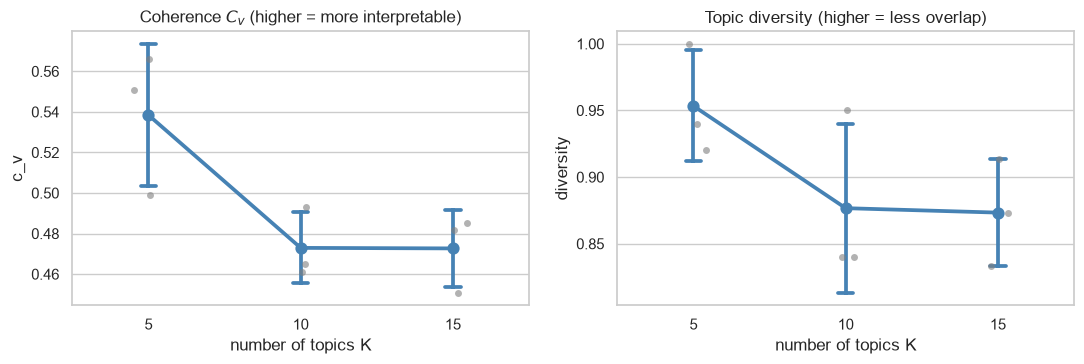

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
titles = {"c_v": "Coherence $C_v$ (higher = more interpretable)", "diversity": "Topic diversity (higher = less overlap)"}
for ax, (metric, title) in zip(axes, titles.items()):
    sns.pointplot(data=scores, x="K", y=metric, errorbar="sd", capsize=0.1, color="steelblue", ax=ax)
    sns.stripplot(data=scores, x="K", y=metric, color="gray", alpha=0.6, ax=ax)
    ax.set(title=title, xlabel="number of topics K", ylabel=metric)
plt.tight_layout()
plt.savefig(FIGURES / "k_comparison.png", dpi=150)
plt.show()

**Interpretation.**
- **K = 5 is the most coherent:** mean $C_v$ ≈ 0.54 vs ≈ 0.47 for K = 10 and K = 15. Even the *worst* K = 5 seed
  (≈ 0.50) beats the *best* K = 10 and K = 15 seeds (≤ 0.49), so the gap is not a lucky initialisation.
- **K = 5 topics barely overlap:** diversity ≈ 0.95 means almost every top word belongs to a single topic. At
  K = 10–15 it drops to ≈ 0.87: the extra topics reuse the same words.
- **Why few topics win here:** the corpus was built from 6 broad fields, so its main structure is coarse. With more
  topics, LDA must split those fields, and part of the splits are built on generic words (see 4.3).
- **The seed matters:** at K = 5 the three runs range from ≈ 0.50 to ≈ 0.57. A single run could have misled us; this
  is why we report mean ± std and keep the best seed for interpretation.
- **Decision:** K = 5 for the main analysis, K = 10 as the comparison. Coherence is only a proxy for human judgement,
  so the choice is checked by reading the topics below.

### 4.2 Selected model: topics and their top words

For the selected K we keep the seed with the highest coherence. Each bar is $P(\text{word} \mid \text{topic})$,
a row of the topic-word matrix $\varphi$. The labels are **our human interpretation** of each word list: LDA itself
only outputs numbered distributions.

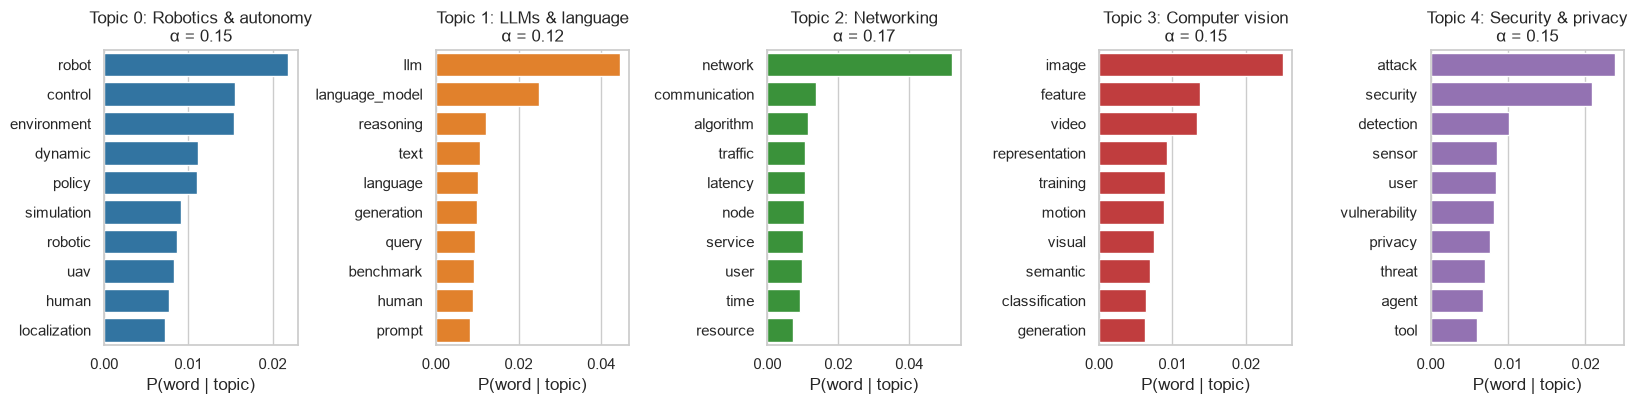

,0: Robotics & autonomy,1: LLMs & language,2: Networking,3: Computer vision,4: Security & privacy
0,robot,llm,network,image,attack
1,control,language_model,communication,feature,security
2,environment,reasoning,algorithm,video,detection
3,dynamic,text,traffic,representation,sensor
4,policy,language,latency,training,user
5,simulation,generation,node,motion,vulnerability
6,robotic,query,service,visual,privacy
7,uav,benchmark,user,semantic,threat
8,human,human,time,classification,agent
9,localization,prompt,resource,generation,tool


In [11]:
BEST_K = 5  # highest mean coherence and lowest variance across seeds (table above)
best_seed = scores.query("K == @BEST_K").nlargest(1, "c_v")["seed"].item()
lda = models[BEST_K, best_seed]

TOPIC_LABELS = {0: "Robotics & autonomy", 1: "LLMs & language", 2: "Networking", 3: "Computer vision", 4: "Security & privacy"}

fig, axes = plt.subplots(1, BEST_K, figsize=(3.3 * BEST_K, 4.2))
for t, ax in enumerate(axes):
    words, probs = zip(*lda.show_topic(t, 10))
    sns.barplot(x=list(probs), y=list(words), color=sns.color_palette("tab10")[t], ax=ax)
    ax.set(title=f"Topic {t}: {TOPIC_LABELS[t]}\nα = {lda.alpha[t]:.2f}", xlabel="P(word | topic)", ylabel="")
plt.tight_layout()
plt.savefig(FIGURES / f"top_words_k{BEST_K}.png", dpi=150)
plt.show()

pd.DataFrame({f"{t}: {TOPIC_LABELS[t]}": [w for w, _ in lda.show_topic(t, 15)] for t in range(BEST_K)})

**Interpretation.**
- **The five topics are easy to name**, and four of them match an arXiv field by their words alone:
  *robot, policy, uav* → cs.RO; *image, video, feature* → cs.CV; *network, traffic, latency* → cs.NI;
  *attack, vulnerability, privacy* → cs.CR. LDA found this structure **without ever seeing the labels**.
- **Topic 1 is "LLMs", not classical NLP:** its top words are *llm, language_model, reasoning, benchmark, prompt*
  rather than *parsing* or *translation*. In 2025, language research is dominated by large language models.
- **There is no database topic.** cs.DB is the smallest category (4.5 % of papers), so its words (*query*, *graph*)
  get absorbed by bigger topics — *query* appears in the LLM topic (retrieval, text-to-SQL). This was the risk
  noted in the dataset section.
- **Topics contain cross-field words:** *uav* and *localization* fall in Robotics (drones, navigation), and the
  Security topic contains *agent, tool, safety*, so it also covers the security of LLM agents.
- **Flat distributions:** the most probable word in each topic has only 2–5 % probability. Topics are broad themes
  spread over many words, not short keyword lists.
- **α ≈ 0.12–0.17 for every topic:** all values are well below 1, so the learned prior favours documents that use
  **few** topics. The values are also close to each other, so no topic is much more frequent a priori.

### 4.3 Comparison: K = 5 vs K = 10

What happens to the topics when we double K? We compare every K = 10 topic with every K = 5 topic using the cosine
similarity of their word distributions (both models share the same vocabulary).

,alpha,top words
0,0.21,"image, video, object, feature, representation, semantic, localization, generation, quality, visual"
1,0.17,"security, network, protocol, attack, node, detection, iot, packet, communication, graph"
2,0.23,"time, algorithm, function, cost, channel, computation, transmission, query, number, scheme"
3,0.16,"traffic, vehicle, uav, motion, environment, indoor, scene, transmission, dynamic, control"
4,0.17,"token, multimodal, radio, query, language_model, visual, retrieval, text, vision_language, semantic"
5,0.11,"language, text, graph, gaussian, decentralized, classification, translation, host, contact, label"
6,0.44,"user, tool, data, sensor, platform, server, design, mobility, field, technology"
7,0.17,"network, latency, service, communication, user, resource, real_time, multi, mobile, edge"
8,0.17,"llm, language_model, attack, reasoning, prompt, vulnerability, benchmark, defense, generation, agent"
9,0.15,"robot, policy, control, agent, environment, action, human, dynamic, simulation, learning"


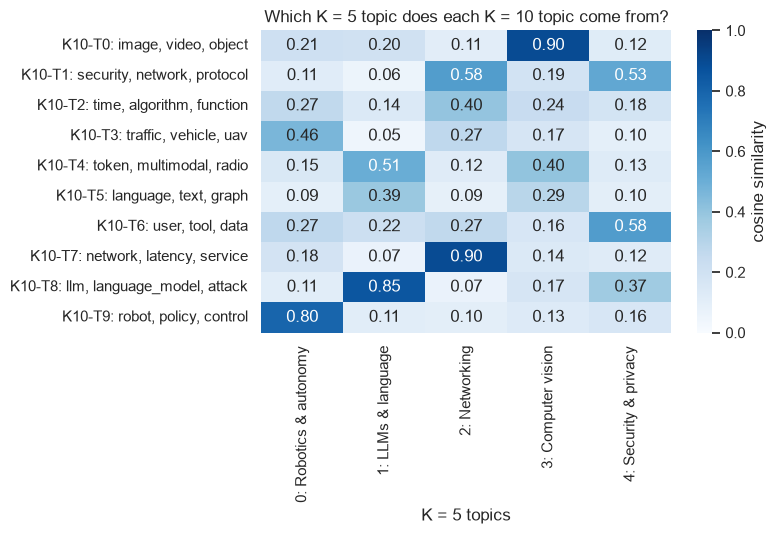

In [12]:
k10_seed = scores.query("K == 10").nlargest(1, "c_v")["seed"].item()
lda10 = models[10, k10_seed]

pd.set_option("display.max_colwidth", None)
display(pd.DataFrame({"alpha": lda10.alpha.round(2),
                      "top words": [", ".join(w for w, _ in lda10.show_topic(t, 10)) for t in range(10)]}))

phi5, phi10 = lda.get_topics(), lda10.get_topics()
phi5, phi10 = (m / np.linalg.norm(m, axis=1, keepdims=True) for m in (phi5, phi10))
similarity = pd.DataFrame(phi10 @ phi5.T, columns=[f"{t}: {TOPIC_LABELS[t]}" for t in range(BEST_K)])
similarity.index = [f"K10-T{t}: {', '.join(w for w, _ in lda10.show_topic(t, 3))}" for t in range(10)]

plt.figure(figsize=(8, 5.5))
sns.heatmap(similarity, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "cosine similarity"})
plt.title("Which K = 5 topic does each K = 10 topic come from?")
plt.xlabel("K = 5 topics")
plt.tight_layout()
plt.savefig(FIGURES / "k5_vs_k10_similarity.png", dpi=150)
plt.show()

**Interpretation.** Doubling K produces three kinds of topics:
- **Stable topics (similarity ≥ 0.8):** Vision, Networking, Robotics and LLMs survive almost unchanged. These
  are the corpus's strongest themes.
- **Meaningful cross-field topics:** *token, multimodal, vision_language* sits between LLMs (0.51) and Vision (0.40),
  which is **vision-language models**. *security, network, protocol, iot* mixes Networking (0.58) and Security (0.53),
  which is **network / IoT security**. *traffic, vehicle, uav* is **autonomous vehicles and drones**. The LLM topic
  also moves toward security (*llm, attack* — similarity 0.37 with Security): **LLM jailbreaks and attacks**. K = 5
  cannot show these interdisciplinary themes.
- **Uninterpretable topics:** *time, algorithm, function, cost* and *user, tool, data, platform* are generic
  vocabulary with no clear field. *language, text, graph, gaussian* mixes unrelated words. About 3 of the 10 topics
  are noise, which explains the lower coherence.

**Takeaway:** K = 5 gives the clearest picture of the main fields. K = 10 finds real interdisciplinary topics, but
at the cost of noisy ones. The best K depends on whether we want a coarse map or finer sub-themes.

## 5. Document-topic distributions

For every paper, LDA infers $\theta_d$: its probability distribution over the 5 topics (a row of the N × K
document-topic matrix). We use it in three ways:
- the **dominant topic** (highest $\theta_d$) works as a soft clustering label;
- the **maximum probability** says how "pure" a paper is;
- papers with two large probabilities are **interdisciplinary**, which hard clustering cannot express.

In [13]:
from gensim.matutils import corpus2dense

theta = corpus2dense(lda.get_document_topics(corpus, minimum_probability=0), num_terms=BEST_K).T  # (N, K)
topic_names = [TOPIC_LABELS[t] for t in range(BEST_K)]
doc_topics = pd.DataFrame(theta, columns=topic_names, index=df.index)

df["dominant_topic"] = doc_topics.idxmax(axis=1)
df["dominant_prob"] = doc_topics.max(axis=1)
df["n_topics_20"] = (doc_topics > 0.2).sum(axis=1)  # topics holding at least 20 % of the paper

print(f"θ matrix: {theta.shape}, rows sum to 1: {np.allclose(theta.sum(axis=1), 1)}")
print(f"Median dominant-topic probability: {df['dominant_prob'].median():.2f}")
print(f"Papers with one topic ≥ 0.8: {(df['dominant_prob'] >= 0.8).mean():.1%} · "
      f"with no topic ≥ 0.5: {(df['dominant_prob'] < 0.5).mean():.1%}")
pd.concat([df[["title", "category"]], doc_topics.round(2)], axis=1).head()

θ matrix: (10197, 5), rows sum to 1: True
Median dominant-topic probability: 0.67
Papers with one topic ≥ 0.8: 29.3% · with no topic ≥ 0.5: 16.2%


,title,category,Robotics & autonomy,LLMs & language,Networking,Computer vision,Security & privacy
0,Labels Generated by Large Language Models Help Measure People's Empathy in Vitro,cs.CL,0.00,0.74,0.06,0.19,0.00
1,PANDA -- Paired Anti-hate Narratives Dataset from Asia: Using an LLM-as-a-Judge to Create the First Chinese Counterspeech Dataset,cs.CL,0.00,0.87,0.00,0.03,0.09
2,Rethinking Addressing in Language Models via Contexualized Equivariant Positional Encoding,cs.CL,0.00,0.26,0.14,0.59,0.00
3,CODEOFCONDUCT at Multilingual Counterspeech Generation: A Context-Aware Model for Robust Counterspeech Generation in Low-Resource Languages,cs.CL,0.11,0.88,0.00,0.00,0.00
4,eRevise+RF: A Writing Evaluation System for Assessing Student Essay Revisions and Providing Formative Feedback,cs.CL,0.00,0.99,0.00,0.00,0.00


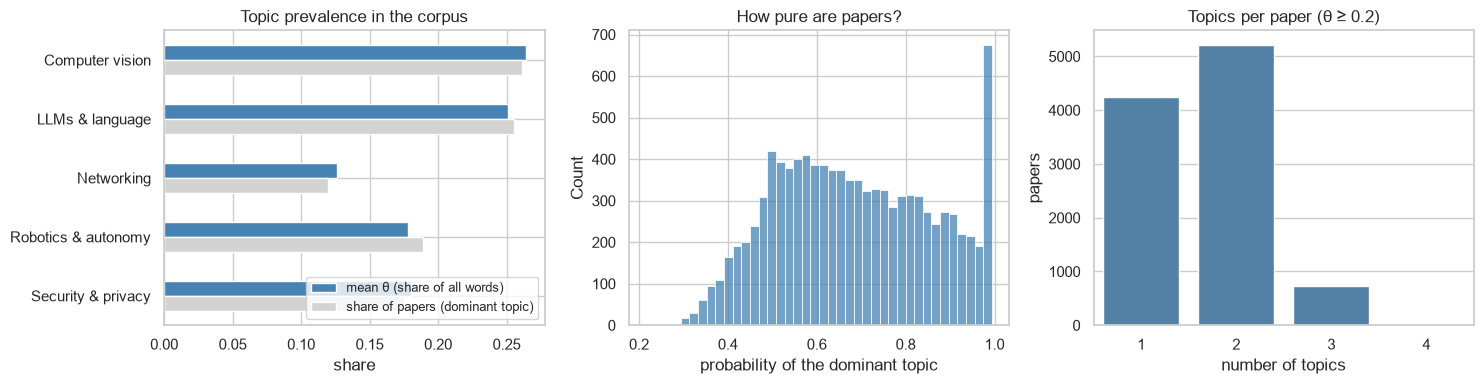

                     mean θ (share of all words)  \
Computer vision                            0.264   
LLMs & language                            0.251   
Networking                                 0.127   
Robotics & autonomy                        0.178   
Security & privacy                         0.180   

                     share of papers (dominant topic)  
Computer vision                                 0.261  
LLMs & language                                 0.255  
Networking                                      0.120  
Robotics & autonomy                             0.189  
Security & privacy                              0.175  


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = dict(zip(topic_names, sns.color_palette("tab10")))

prevalence = pd.DataFrame({"mean θ (share of all words)": doc_topics.mean(),
                           "share of papers (dominant topic)": df["dominant_topic"].value_counts(normalize=True)})
prevalence.plot.barh(ax=axes[0], color=["steelblue", "lightgray"])
axes[0].legend(loc="lower right", fontsize=9)
axes[0].set(title="Topic prevalence in the corpus", xlabel="share")
axes[0].invert_yaxis()

sns.histplot(df["dominant_prob"], bins=40, color="steelblue", ax=axes[1])
axes[1].set(title="How pure are papers?", xlabel="probability of the dominant topic")

sns.countplot(x=df["n_topics_20"], color="steelblue", ax=axes[2])
axes[2].set(title="Topics per paper (θ ≥ 0.2)", xlabel="number of topics", ylabel="papers")
plt.tight_layout()
plt.savefig(FIGURES / "doc_topic_overview.png", dpi=150)
plt.show()

print(prevalence.round(3))

**Interpretation.**
- **Most papers mix topics:** about 4,200 papers have one topic above 0.2, about 5,200 have **two**, and about 700
  have three. A majority of papers are better described as a mixture than by one label, which is why we chose a
  mixed-membership model.
- **Typical purity:** the median dominant probability is 0.67. 29 % of papers have one topic ≥ 0.8, and 16 % have
  no topic above 0.5. The spike near 1.0 (~670 papers) contains very focused papers (examples in 5.1).
- **Prevalence:** Vision (26 %) and LLMs (25 %) are the largest topics, Networking the smallest (13 %). Both views
  (mean θ and share of dominant papers) agree, so the result is not an artefact of the argmax.
- **Topics ≠ categories in size:** cs.CV and cs.CL are each ~22 % of the papers, but their topics hold 25–26 % of
  all words. They **absorb words from other fields**: robots use vision, security papers study LLMs. Conversely,
  Robotics (18 % vs cs.RO 22 %) and Security (18 % vs cs.CR 21 %) lose part of their papers' words to other topics.

### 5.1 Representative papers per topic

The papers with the highest probability for each topic are the best "prototypes" of that topic. Reading their
titles is a direct check of our human labels.

In [15]:
pd.set_option("display.max_colwidth", 110)
examples = pd.concat([
    df.assign(topic=name, prob=doc_topics[name]).nlargest(3, "prob")[["topic", "prob", "category", "title"]]
    for name in topic_names
])
examples.round(3).set_index(["topic", "prob"])

category  \
topic               prob             
Robotics & autonomy 0.994    cs.RO   
                    0.993    cs.RO   
                    0.991    cs.RO   
LLMs & language     0.994    cs.CL   
                    0.994    cs.CL   
                    0.993    cs.DB   
Networking          0.993    cs.NI   
                    0.993    cs.NI   
                    0.992    cs.NI   
Computer vision     0.994    cs.CV   
                    0.994    cs.CV   
                    0.994    cs.CV   
Security & privacy  0.993    cs.CR   
                    0.993    cs.NI   
                    0.993    cs.CR   

                                                                                                                                   title  
topic               prob                                                                                                                  
Robotics & autonomy 0.994          FERMI: Flexible Radio Mapping with a Hybrid Propagation Model and Scalable Autonomous Data Collection  
                    0.993                                   Wheel-GINS: A GNSS/INS Integrated Navigation System with a Wheel-mounted IMU  
                    0.991                            Performance Evaluation of Trajectory Tracking Controllers for a Quadruped Robot Leg  
LLMs & language     0.994  Prompt-oriented Output of Culture-Specific Items in Translated African Poetry by Large Language Model: An ...  
                    0.994                       HERITAGE: An End-to-End Web Platform for Processing Korean Historical Documents in Hanja  
                    0.993                                       NLI4DB: A Systematic Review of Natural Language Interfaces for Databases  
Networking          0.993                  PartialLoading: User Scheduling and Bandwidth Allocation for Parameter-sharing Edge Inference  
                    0.993               Relay Selection and User Equipment Admission in Resource-Efficient NextG Sidelink Communications  
                    0.992  Geminet: Learning the Duality-based Iterative Process for Lightweight Traffic Engineering in Changing Topo...  
Computer vision     0.994             Separate Motion from Appearance: Customizing Motion via Customizing Text-to-Video Diffusion Models  
                    0.994                                 Through-The-Mask: Mask-based Motion Trajectories for Image-to-Video Generation  
                    0.994                                                                    Motion-Aware Generative Frame Interpolation  
Security & privacy  0.993                                                                   Online Authentication Habits of Indian Users  
                    0.993             Intractable Cookie Crumbs: Unveiling the Nexus of Stateful Banner Interaction and Tracking Cookies  
                    0.993  Aggregating Digital Identities through Bridging. An Integration of Open Authentication Protocols for Web3 ...

**Interpretation.**
- **The labels are confirmed:** the prototypes have θ ≈ 0.99, and their titles clearly belong to the topic: quadruped
  controllers and GNSS/INS navigation for Robotics, text-to-video diffusion for Vision, bandwidth allocation and
  traffic engineering for Networking, authentication habits and cookies for Security.
- **13 of 15 prototypes come from the expected category.** The two exceptions are informative:
  - *NLI4DB: Natural Language Interfaces for Databases* (cs.DB) is a perfect LLMs & language prototype. This
    explains where cs.DB papers go (see 5.3).
  - *Intractable Cookie Crumbs* (cs.NI) is about tracking cookies, which really is a privacy topic. Here the
    arXiv label, not LDA, is debatable.
- Prototypes use **highly specific vocabulary**, so they are the easiest papers. The difficult cases are the
  mixed papers below.

### 5.2 Mixed (interdisciplinary) papers

We look for papers whose **two** largest topics each hold at least 35 % of the paper, and show the most balanced
ones.

Papers with two topics ≥ 0.35: 2,085 (20.4%)


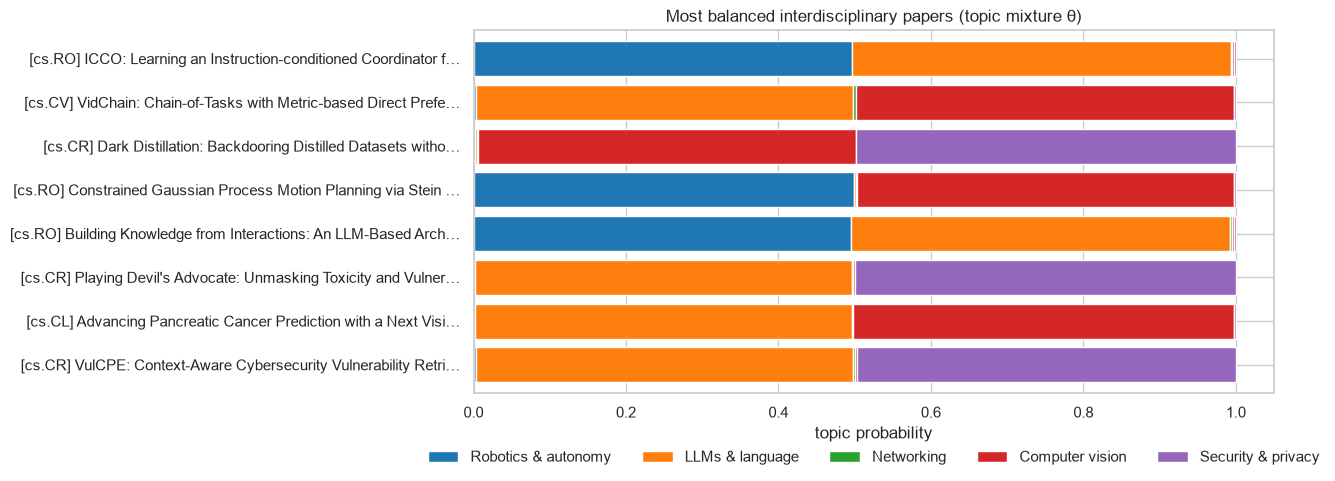

In [16]:
top2 = np.sort(theta, axis=1)[:, -2]  # second-largest probability per paper
mixed = df.assign(second_prob=top2).query("second_prob >= 0.35").nlargest(8, "second_prob")
print(f"Papers with two topics ≥ 0.35: {(top2 >= 0.35).sum():,} ({(top2 >= 0.35).mean():.1%})")

short_titles = [f"[{c}] {t[:55]}{'…' if len(t) > 55 else ''}" for c, t in zip(mixed["category"], mixed["title"])]
mix = doc_topics.loc[mixed.index].set_axis(short_titles)
mix.plot.barh(stacked=True, figsize=(13, 5), color=[colors[n] for n in topic_names], width=0.8)
plt.gca().invert_yaxis()
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=BEST_K, frameon=False)
plt.title("Most balanced interdisciplinary papers (topic mixture θ)")
plt.xlabel("topic probability")
plt.tight_layout()
plt.savefig(FIGURES / "mixed_papers.png", dpi=150, bbox_inches="tight")  # keep the legend below the axes
plt.show()

**Interpretation.**
- **20 % of papers (2,085) have two topics ≥ 0.35.** The most balanced ones are close to 50/50 and are recognisable
  interdisciplinary research:
  - *Robotics + LLMs:* language-guided robot coordination, LLM-based architectures for robots;
  - *LLMs + Vision:* video understanding with preference optimisation;
  - *LLMs + Security:* toxicity and vulnerabilities of language models, vulnerability retrieval;
  - *Vision + Security:* backdoor attacks on distilled (image) datasets.
- These are the **same cross-field themes the K = 10 model found as separate topics** (section 4.3). K = 5
  represents them as mixtures instead, which is a more compact description.
- **A visible limitation:** *pancreatic cancer prediction* (cs.CL) is split between LLMs and Vision. There is no
  medical topic, so medical words attach to the closest existing topic (medical imaging → Vision). With K = 5,
  minor themes are forced into the big ones.

### 5.3 Do topics match the arXiv categories?

The `category` label was never given to LDA, so it is an independent check. Two views:
- **hard:** share of each category's papers whose *dominant* topic is X (rows sum to 1);
- **soft:** average topic mixture $\theta$ of each category's papers (rows sum to 1).

We also report NMI and ARI between dominant topic and category (0 = unrelated, 1 = identical partitions).

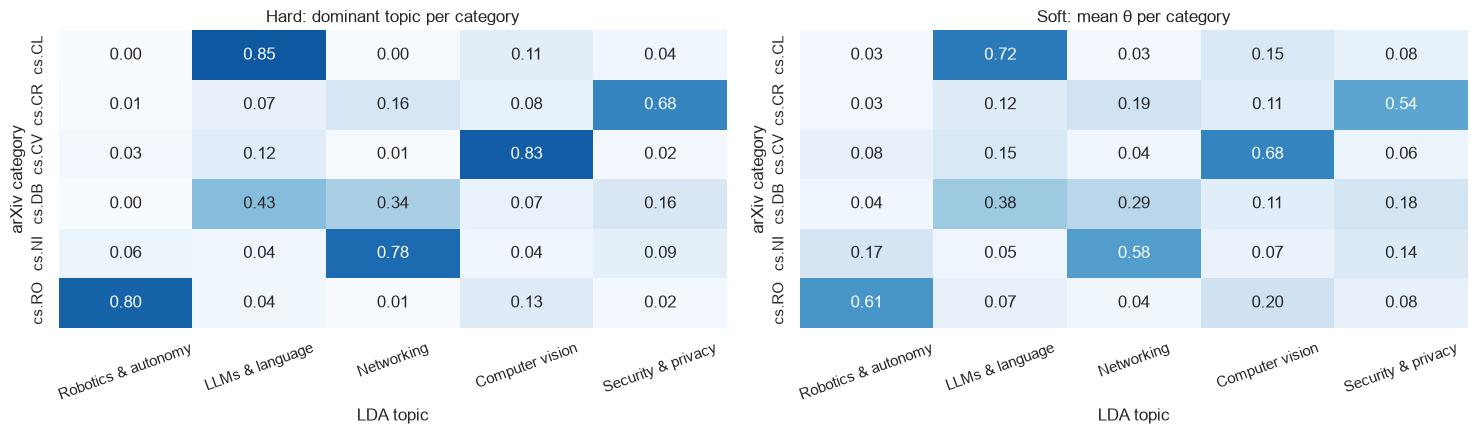

NMI = 0.510 · ARI = 0.521


In [17]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

hard = pd.crosstab(df["category"], df["dominant_topic"], normalize="index").reindex(columns=topic_names, fill_value=0)
soft = doc_topics.groupby(df["category"]).mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, matrix, title in zip(axes, (hard, soft), ("Hard: dominant topic per category", "Soft: mean θ per category")):
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set(title=title, xlabel="LDA topic", ylabel="arXiv category")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(FIGURES / "category_topic_heatmap.png", dpi=150)
plt.show()

print(f"NMI = {normalized_mutual_info_score(df['category'], df['dominant_topic']):.3f} · "
      f"ARI = {adjusted_rand_score(df['category'], df['dominant_topic']):.3f}")

**Interpretation.**
- **Strong diagonal:** most papers of cs.CL (85 %), cs.CV (83 %), cs.RO (80 %) and cs.NI (78 %) fall into "their"
  topic. NMI = 0.51 and ARI = 0.52 show **moderate agreement**. LDA recovers most of the field structure from words
  alone, but topics are not a copy of the labels. That is expected, because authors choose a single category while
  topics describe vocabulary.
- **cs.CR has the lowest agreement (68 %):** its papers spread into Networking (16 %) and LLMs (7 %). Security is
  defined by its *goal* (protecting something), not by a vocabulary, so it borrows the words of what it protects
  (networks, LLMs, images).
- **The off-diagonal cells show real cross-field research:** cs.RO → Vision (13 % hard, 20 % soft: robot perception),
  cs.CV → LLMs (12 %: vision-language models), cs.CL → Vision (11 %: multimodal models).
- **cs.DB has no topic of its own.** It splits between LLMs (43 %: natural-language interfaces, text-to-SQL),
  Networking (34 %: distributed systems, query processing) and Security (16 %: blockchain, data governance).
  This confirms the size problem noted in sections 1 and 4.2.
- **The soft view is less concentrated (0.54–0.72 on the diagonal):** even its "own" topic explains only about
  two thirds of a category's words.

### 5.4 Error analysis: papers whose topic disagrees with their category

We map each category to the topic most of its papers fall into, then read confidently "misplaced" papers
(dominant probability ≥ 0.6). Are these LDA errors, or papers that really belong to another field?

In [18]:
expected_topic = hard.idxmax(axis=1)
df["agrees"] = df["dominant_topic"] == df["category"].map(expected_topic)
print("Expected topic per category:", expected_topic.to_dict())
print(f"Agreement with expected topic: {df['agrees'].mean():.1%}")
print(df.groupby("category")["agrees"].mean().round(3).to_string())

misplaced = df.query("not agrees and dominant_prob >= 0.6")
(misplaced.sample(frac=1, random_state=SEED).groupby("category").head(2).sort_values("category")
          [["category", "dominant_topic", "dominant_prob", "title"]].round(2))

Expected topic per category: {'cs.CL': 'LLMs & language', 'cs.CR': 'Security & privacy', 'cs.CV': 'Computer vision', 'cs.DB': 'LLMs & language', 'cs.NI': 'Networking', 'cs.RO': 'Robotics & autonomy'}
Agreement with expected topic: 77.2%
category
cs.CL    0.846
cs.CR    0.677
cs.CV    0.826
cs.DB    0.431
cs.NI    0.776
cs.RO    0.802


,category,dominant_topic,dominant_prob,title
965,cs.CL,Computer vision,0.79,Weak Supervision Dynamic KL-Weighted Diffusion Models Guided by Large Language Models
1172,cs.CL,Computer vision,0.70,PGB: One-Shot Pruning for BERT via Weight Grouping and Permutation
8288,cs.CR,Networking,0.63,Enabling Deep Visibility into VxWorks-Based Embedded Controllers in Cyber-Physical Systems for Anomaly Det...
7609,cs.CR,Networking,0.61,LiteChain: A Lightweight Blockchain for Verifiable and Scalable Federated Learning in Massive Edge Networks
2559,cs.CV,LLMs & language,0.69,Improving Image Captioning by Mimicking Human Reformulation Feedback at Inference-time
2491,cs.CV,LLMs & language,0.61,Local Compositional Complexity: How to Detect a Human-readable Messsage
9102,cs.DB,Security & privacy,0.68,FairDAG: Consensus Fairness over Multi-Proposer Causal Design
9155,cs.DB,Security & privacy,0.69,Assessing FAIRness of the Digital Shadow Reference Model
10080,cs.NI,Security & privacy,0.64,Towards Network Data Analytics in 5G Systems and Beyond
10194,cs.NI,Robotics & autonomy,0.65,How Long Can I Transmit? A Mobility Aware mmWave-based UAV Communication Framework


**Interpretation.** Overall, 77 % of papers fall into their category's expected topic (43 % for cs.DB,
which has no topic of its own). Reading the confident "misplaced" papers shows two different situations:
- **LDA is arguably right, and the single label is too coarse:** image captioning (cs.CV → LLMs), LLM-guided
  diffusion models (cs.CL → Vision), mmWave **UAV** communication (cs.NI → Robotics), X-ray 3D reconstruction
  (cs.RO → Vision), blockchain for federated learning in edge networks (cs.CR → Networking).
- **Real LDA errors caused by shared vocabulary:** *one-shot pruning for BERT* (cs.CL → Vision): words like
  *pruning, weight, compression* are more frequent in vision efficiency papers. *FairDAG consensus* (cs.DB → Security):
  blockchain vocabulary pulls it toward Security. A bag-of-words model sees *which* words are used, not *why*.

**Conclusion:** the 23 % disagreement is not all error. Many of these papers really belong to two fields, and an
arXiv category can only name one.

### 5.5 Interactive view (pyLDAvis)

Left: topics as circles. Size = topic prevalence, distance = how different their word distributions are (2-D metric
MDS of the Jensen-Shannon distances). Right: top words of the selected topic. Lowering λ ranks words by how
**specific** they are to the topic rather than how frequent. The HTML is saved to `figures/ldavis_k5.html`.

*`mds="mmds"` is used because the default PCoA projection produces complex numbers with recent NumPy versions.*

In [19]:
import warnings

import pyLDAvis
import pyLDAvis.gensim_models

with warnings.catch_warnings():  # sklearn deprecation notices triggered inside pyLDAvis
    warnings.simplefilter("ignore", FutureWarning)
    vis = pyLDAvis.gensim_models.prepare(lda, corpus, dictionary, sort_topics=False, mds="mmds")
pyLDAvis.save_html(vis, str(FIGURES / f"ldavis_k{BEST_K}.html"))
print("pyLDAvis numbers topics from 1:", {i + 1: name for i, name in enumerate(topic_names)})
pyLDAvis.display(vis)

pyLDAvis numbers topics from 1: {1: 'Robotics & autonomy', 2: 'LLMs & language', 3: 'Networking', 4: 'Computer vision', 5: 'Security & privacy'}


**Interpretation** (positions from the saved HTML; metric MDS with a fixed `random_state=0`).
- **No circles overlap**, so the five topics have clearly different word distributions, which is consistent with the
  high topic diversity (0.95).
- **Closest pairs:** LLMs–Security (the LLM attack/safety papers), then Networking–Vision and Robotics–Vision
  (robot perception). These match the off-diagonal cells of the heatmap.
- **Farthest pairs:** Robotics–Networking and Networking–Security. Their vocabularies barely overlap at K = 5.
- **Caveat:** a 2-D map of 5 topics distorts distances. Read it as "which topics are near" rather than as exact
  values.
- **Suggested demo for the presentation:** select the LLMs topic and lower λ to ~0.3. Shared words
  like *language* and *text* drop down the list, and words used almost only in LLM papers rise to the top.

## 6. Limitations

Each limitation below was **observed in our own results**, with the section where it appears.

**Data**

| Limitation | Evidence | Consequence |
|---|---|---|
| Unbalanced categories | cs.DB has 462 papers (4.5 %), cs.NI 874 (§1) | cs.DB gets **no topic of its own** and splits across three topics, with 43 % agreement (§4.2, §5.3, §5.4). |
| Short, uneven time window | cs.CV and cs.CL cover only 6–7 weeks of early 2025, cs.DB and cs.NI the full 6 months (§1) | Topics describe an **early-2025 snapshot** (LLM-heavy). They say nothing about trends over time. |
| Six hand-picked, distinct fields | cs.LG was excluded because it overlaps everything (`fetch_arxiv.py`) | The task is easier than real arXiv. On all CS papers, topics would overlap much more. |
| Abstracts only | ~175 words per paper (§1) | Methods and results in the full text are invisible to the model. |

**Representation and model**

| Limitation | Evidence | Consequence |
|---|---|---|
| Bag-of-words ignores word order and meaning | *BERT pruning* → Vision, *FairDAG consensus* → Security (§5.4) | Papers sharing words but not purpose get confused. Ambiguous words (*network*: neural vs computer, *attention*) are only partly fixed by bigrams. |
| Stop-word list partly tuned after reading topics | $C_v$ 0.48 → 0.54 after adding filler words (§4.1) | Some subjectivity, so we documented it. A different analyst could choose other words. |
| Choice of K | K = 5 is more coherent, K = 10 finds cross-field topics but also noise (§4.3) | No single "true" K. Only 5, 10 and 15 were tested (not K = 6 = number of categories, nor a finer sweep). |
| Sensitivity to initialisation | $C_v$ from 0.50 to 0.57 across 3 seeds at K = 5 (§4) | One run is not reliable. 3 seeds is a minimum, not a guarantee. |
| Small topics forced into big ones | Pancreatic cancer paper split LLMs / Vision (§5.2) | With K = 5, minor themes (medical, databases) have no topic of their own. |

**Evaluation**

| Limitation | Evidence | Consequence |
|---|---|---|
| Coherence is only a proxy | Chosen K was confirmed by reading topics (§4.2) | High $C_v$ does not guarantee useful topics. Human reading is still needed. |
| arXiv labels are single-choice | 20 % of papers have two topics ≥ 0.35 (§5.2), and many "errors" are interdisciplinary (§5.4) | NMI / ARI (≈ 0.51) **underestimate** quality: they penalise legitimate mixtures. |
| Topic labels are our interpretation | LDA only outputs numbered distributions (§4.2) | Names like "LLMs & language" are human summaries and could be debated. |

**Possible improvements**
- Collect a **balanced** sample (same number of papers per category over the same period) so small fields can form
  their own topic, and a multi-year window to study topic evolution (dynamic topic models).
- Run a finer K sweep (e.g. 4–20) with more seeds, and include K = 6.
- Compare with an embedding-based topic model (e.g. BERTopic), which captures meaning beyond shared words and would
  address the vocabulary-confusion errors.

## 7. Conclusion

**What we built.** A reproducible pipeline: arXiv API → cleaning and spaCy lemmatization → bigrams and
Bag-of-Words → gensim LDA. We compared K = 5, 10 and 15 over 3 seeds each, then checked the topics against
arXiv categories the model never saw.

**What we observed.**
- K = 5 gives five coherent, clearly separated topics ($C_v$ ≈ 0.54, diversity 0.95): Robotics & autonomy,
  LLMs & language, Networking, Computer vision, Security & privacy.
- Four topics match an arXiv field. The language topic is really about **LLMs**, which also appear in security,
  robotics and vision papers.
- **Most papers are mixtures:** about half have two topics with θ ≥ 0.2. Dominant topics agree with categories for
  77 % of papers (NMI 0.51).
- K = 10 reveals interdisciplinary themes (vision-language models, network/IoT security, LLM attacks), but also
  noise topics.

**What we learned.**
1. **Preprocessing mattered more than tuning:** removing field-neutral words improved coherence more than any
   change of K.
2. **Metrics guide, reading decides:** coherence chose K = 5, but only reading the top words and example papers told
   us whether the topics made sense.
3. **"Disagreement" is not always "error":** many papers LDA "misplaces" really belong to two fields. Mixed
   membership is LDA's main advantage over a single label or a hard clustering.
4. **Bag-of-words is LDA's main limit:** it sees which words are used, not why, so it confuses papers that share
   vocabulary.

**Main takeaway:** without any labels, LDA recovered the main research fields of 10,000 arXiv abstracts and showed
that a large share of current CS research, much of it driven by LLMs, sits *between* fields rather than inside
one.